In [1]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
from itertools import product
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load your main file
df = pd.read_json("gpt-5.2_merged_summ_eval.jsonl", lines=True)

# Identify all LLM evaluators
llm_columns = [col for col in df.columns if col.startswith(('zs_', 'pers_'))]

# Identify all baselines: Expert, Crowd, ROUGE, BERTScore
baseline_columns = [col for col in df.columns if col.startswith(('Expert_', 'Crowd_')) or 'ROUGE' in col or 'BERTScore' in col]

all_cols = llm_columns + baseline_columns
# Initialize empty correlation matrix (rows: LLMs, cols: baselines)
correlation_matrix = pd.DataFrame(index=all_cols, columns=all_cols)

# Fill the matrix with Pearson correlation coefficients
for llm, base in product(llm_columns, baseline_columns):
    try:
        corr, _ = pearsonr(df[llm], df[base])
        correlation_matrix.loc[llm, base] = corr
    except:
        correlation_matrix.loc[llm, base] = np.nan

# Convert all values to float
correlation_matrix = correlation_matrix.astype(float)

# Optionally, save to CSV
correlation_matrix.to_csv("llm_vs_baseline_correlation_matrix.csv")

# Preview
print(correlation_matrix.head())

                zs_fluency  zs_coherence  zs_consistency  zs_relevance  \
zs_fluency             NaN           NaN             NaN           NaN   
zs_coherence           NaN           NaN             NaN           NaN   
zs_consistency         NaN           NaN             NaN           NaN   
zs_relevance           NaN           NaN             NaN           NaN   
pers_fluency           NaN           NaN             NaN           NaN   

                pers_fluency  pers_coherence  pers_consistency  \
zs_fluency               NaN             NaN               NaN   
zs_coherence             NaN             NaN               NaN   
zs_consistency           NaN             NaN               NaN   
zs_relevance             NaN             NaN               NaN   
pers_fluency             NaN             NaN               NaN   

                pers_relevance   ROUGE-1   ROUGE-2   ROUGE-L  BERTScore  \
zs_fluency                 NaN  0.012025  0.059479  0.089451   0.251845   
zs_coher

In [3]:
df_numeric = df.select_dtypes(include='number')

# --- Pearson Correlation ---
pearson_corr = df_numeric.corr(method='pearson')

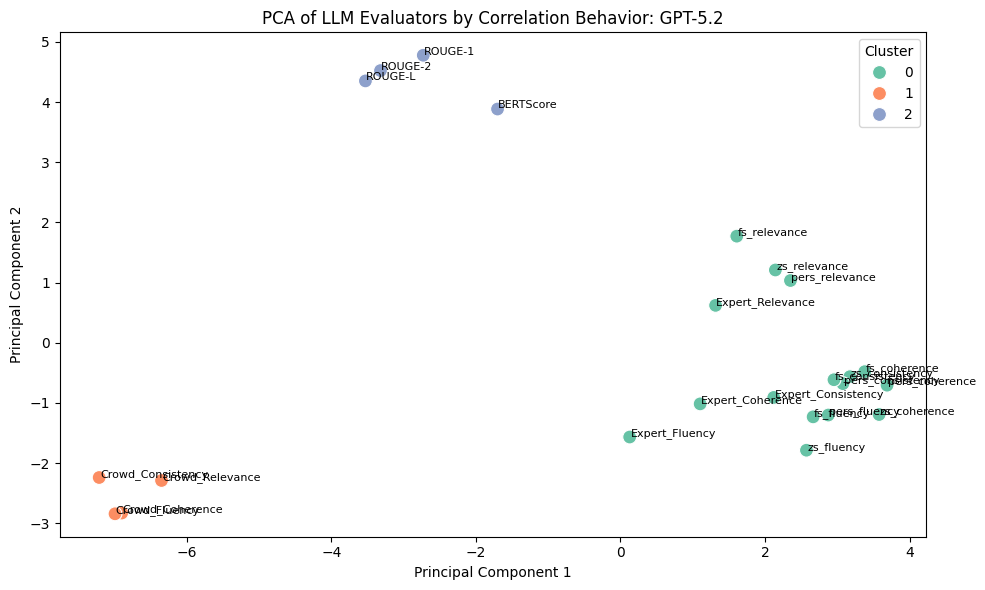

In [4]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# Optional: standardize if not done already
from sklearn.preprocessing import StandardScaler
scaled_matrix = StandardScaler().fit_transform(pearson_corr)

# Run PCA to reduce to 2D
pca = PCA(n_components=2)
pca_components = pca.fit_transform(scaled_matrix)

# Run KMeans clustering (choose k=3 for now, can be optimized later)
kmeans = KMeans(n_clusters=3, random_state=42)
cluster_labels = kmeans.fit_predict(pca_components)

# Plot PCA with cluster labels
plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_components[:, 0], y=pca_components[:, 1],
                hue=cluster_labels, palette='Set2', s=100)

# Annotate each point with the LLM evaluator name
for i, evaluator in enumerate(pearson_corr.index):
    plt.text(pca_components[i, 0]+0.01, pca_components[i, 1]+0.01,
             evaluator, fontsize=8)

plt.title("PCA of LLM Evaluators by Correlation Behavior: GPT-5.2")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


# Prompt Similarity

In [5]:
prompt_types = ['zs', 'pers']
dimensions = ['fluency', 'coherence', 'consistency', 'relevance']

# Build list of tuples: (LLM_col, Expert_col)
rows = []
for pt in prompt_types:
    for dim in dimensions:
        llm_col = f"{pt}_{dim}"
        expert_col = f"Expert_{dim.capitalize()}"
        if llm_col in df.columns and expert_col in df.columns:
            corr, pval = pearsonr(df[llm_col], df[expert_col])
            rows.append({'Prompt': pt, 'Dimension': dim, 'Correlation': corr, 'p_value': pval})

# Build tidy DataFrame
correlation_matrix = pd.DataFrame(rows)

# Optional: Pivot to matrix form (Prompt × Dimension)
matrix_form = correlation_matrix.pivot(index='Prompt', columns='Dimension', values='Correlation')
print(matrix_form)

Dimension  coherence  consistency   fluency  relevance
Prompt                                                
pers        0.573804     0.762261  0.467126   0.560508
zs          0.544256     0.828761  0.421065   0.572753


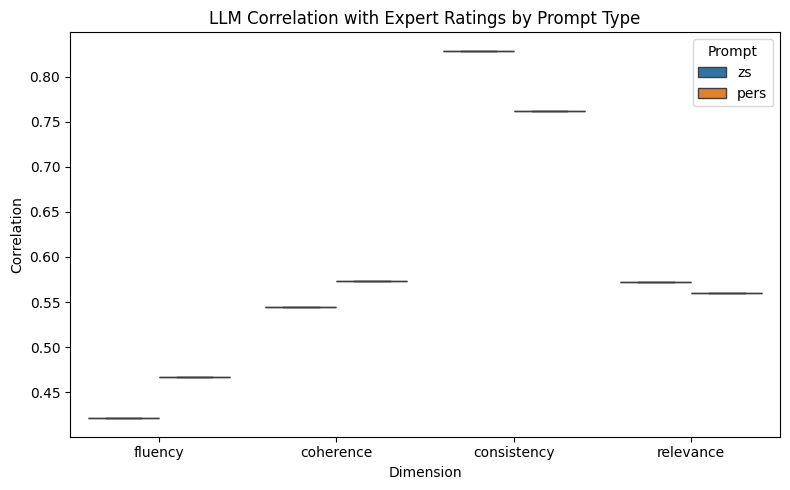

                sum_sq   df          F    PR(>F)
C(Prompt)     0.000001  1.0   0.000974  0.977058
C(Dimension)  0.130042  3.0  34.383144  0.007997
Residual      0.003782  3.0        NaN       NaN


In [6]:
# Create a tidy dataframe: rows = (prompt_type, dimension), column = correlation with expert
data = []

for pt in prompt_types:
    for dim in dimensions:
        row_name = f"{pt}_{dim}"
        col_name = f"Expert_{dim.capitalize()}"
        corr_val = pearson_corr.loc[row_name, col_name]
        data.append({'Prompt': pt, 'Dimension': dim, 'Correlation': corr_val})

prompt_df = pd.DataFrame(data)

# Step 2: Plot boxplot of correlations
plt.figure(figsize=(8,5))
sns.boxplot(data=prompt_df, x='Dimension', y='Correlation', hue='Prompt')
plt.title("LLM Correlation with Expert Ratings by Prompt Type")
plt.tight_layout()
plt.show()

# Step 3: Statistical Test — Repeated Measures ANOVA or Friedman Test (non-parametric)
from statsmodels.stats.anova import AnovaRM

# Pivot data for repeated-measures ANOVA
anova_data = prompt_df.pivot(index='Dimension', columns='Prompt', values='Correlation').reset_index()

# Convert to long form for statsmodels
anova_long = pd.melt(anova_data, id_vars=['Dimension'], value_vars=prompt_types,
                     var_name='Prompt', value_name='Correlation')

# Repeated measures ANOVA
import statsmodels.api as sm
from statsmodels.formula.api import ols

model = ols('Correlation ~ C(Prompt) + C(Dimension)', data=anova_long).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

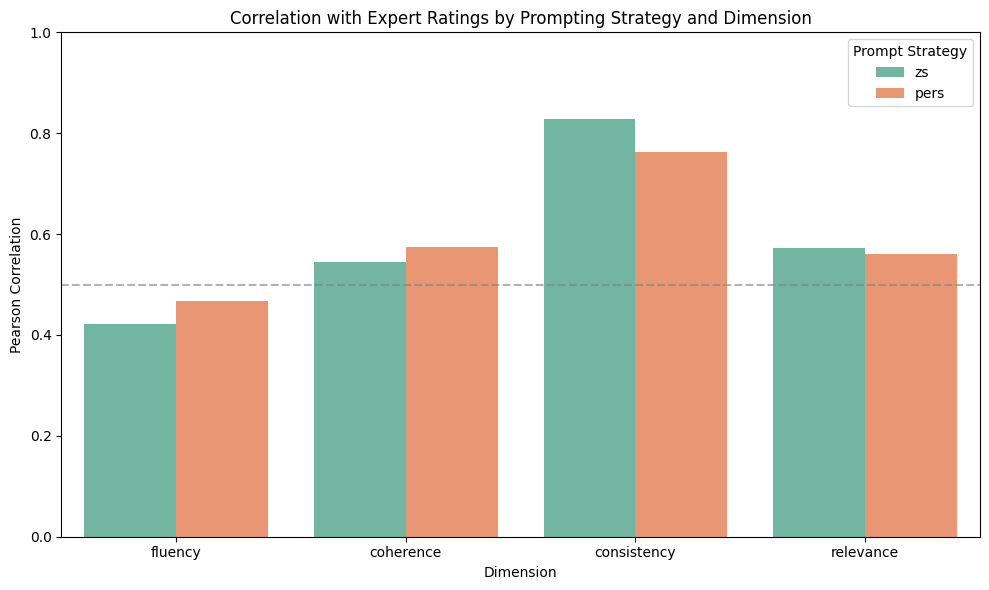

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming your tidy dataframe from earlier is still available:
# Columns: ['Prompt', 'Dimension', 'Correlation']

plt.figure(figsize=(10, 6))
sns.barplot(
    data=correlation_matrix,
    x='Dimension',
    y='Correlation',
    hue='Prompt',
    palette='Set2'
)

plt.title("Correlation with Expert Ratings by Prompting Strategy and Dimension")
plt.ylabel("Pearson Correlation")
plt.ylim(0, 1)
plt.axhline(0.5, linestyle='--', color='gray', alpha=0.6)
plt.legend(title='Prompt Strategy')
plt.tight_layout()
plt.show()
